#  **From Zama-Zamas to ESG Scores**
### AI Framework for Quantifying Illegal Mining Risk (IMR) in South African Investment Portfolios


#### ***Student:*** Tebogo John Maphutha
#### **Module:** NCPS730
#### **Institution:** Sol Plaatje University



#### **Project Overview**
This notebook builds a complete **Illegal Mining Risk (IMR) scoring model** using the *Operating Mines of South Africa (Feb 2026)* dataset from Mendeley Data.

The model assigns each mine a risk score between **0 (low risk)** and **100 (high risk)** based on features that are known to correlate with illegal mining exposure in South Africa.

### Notebook Structure
1. Install & Import Libraries
2. Load the Dataset
3. Exploratory Data Analysis (EDA)
4. Data Cleaning & Preparation
5. Feature Engineering
6. Build the IMR Risk Score (Rule-Based)
7. Train Machine Learning Models
8. Model Evaluation (Accuracy, F1, ROC-AUC)
9. SHAP Interpretability Analysis
10. Export Results for Power BI Dashboard


## (1) Installing & Importing requred  Libraries

In [2]:

!pip install shap xgboost openpyxl --quiet

In [4]:
# main Libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization Tools
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
sns.set_theme(style='whitegrid', palette='muted')

# Machine Learning Tools
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.metrics import (
    accuracy_score, classification_report,
    roc_auc_score, roc_curve, confusion_matrix,
    f1_score, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier

# SHAP (Model Interpretability)
import shap

print('All required libraries imported')

All required libraries imported


---
## (2) Reading in the Dataset

In [5]:
#  Upload the dataset file when prompted

from google.colab import files
print('Upload your Dataset')
uploaded = files.upload()

Upload your Dataset


Saving All-Operating-Mines-SA-Feb2026.xlsx to All-Operating-Mines-SA-Feb2026.xlsx


In [6]:

df = pd.read_excel('All-Operating-Mines-SA-Feb2026.xlsx', sheet_name='data')

print(f'Dataset Loaded')
print(f'Shape: {df.shape[0]} mines × {df.shape[1]} columns')
print(f'\n Columns:')
for col in df.columns:
    print(f'  - {col}')

Dataset Loaded
Shape: 245 mines × 16 columns

 Columns:
  - MineID
  - Mine Name
  - Other Name
  - Mining right
  - Tailings Dam
  - Owner
  - Previous owner
  - Company Type
  - Primary Commodity
  - Mining Method
  - Life of Mine
  - Workforce
  - Start year
  - Latitude
  - Longitude
  - Farms


In [7]:
# first five rows
print('first five rows:')
df.head()

first five rows:


,MineID,Mine Name,Other Name,Mining right,Tailings Dam,Owner,Previous owner,Company Type,Primary Commodity,Mining Method,Life of Mine,Workforce,Start year,Latitude,Longitude,Farms
0,201,Koffiefontein,NaN,NaN,NaN,Stargems,Petra Diamonds,Major,diamonds,underground,2041.0,NaN,1878.0,-29.415200,24.992330,KOFFIEFONTEIN 733
1,202,Lace,NaN,NaN,NaN,DiamondCorp,De Beers,Junior,diamonds,open cast,2041.0,NaN,1901.0,-27.444504,27.124435,RUBY 691
2,203,Joel,NaN,NaN,NaN,Harmony,NaN,Major,gold,conventional underground,2030.0,2042.0,1987.0,-28.276392,26.813437,Leeuwfonteinswerft 51; Leeuwfonteinswerft 256
3,204,Masimong 5 shaft,NaN,NaN,NaN,Harmony,NaN,Major,gold,conventional underground,2027.0,2089.0,1947.0,-27.973325,26.877733,Erfdeel 188
4,205,Tshepong North,NaN,NaN,NaN,Harmony,NaN,Major,gold,conventional deep underground,2031.0,3765.0,1991.0,-27.865808,26.712355,Free State Geduld 448


---
### (3) Exploratory Data Analysis (EDA)

In [8]:
#Summary Statistics
print('Dataset Summary Statistics:')
df.describe(include='all')

Dataset Summary Statistics:


,MineID,Mine Name,Other Name,Mining right,Tailings Dam,Owner,Previous owner,Company Type,Primary Commodity,Mining Method,Life of Mine,Workforce,Start year,Latitude,Longitude,Farms
count,245.000000,245,25,10,13,245,15,243,245,245,165.000000,50.000000,157.000000,245.000000,245.000000,194
unique,NaN,242,22,4,7,130,6,4,18,18,NaN,NaN,NaN,NaN,NaN,184
top,NaN,Elandsfontein,Wolvekrans and Ifalethu,GP30/5/1/2/2(51) MR,Leeudoorn TSF,Sibanye-Stillwater,Gold Fields,Major,coal,open cast,NaN,NaN,NaN,NaN,NaN,Free State Geduld 448
freq,NaN,2,2,4,3,18,9,148,90,93,NaN,NaN,NaN,NaN,NaN,2
mean,598.906122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2043.363636,2985.740000,1981.949045,-26.248861,27.804684,NaN
std,167.407827,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.738305,2550.148325,83.681156,1.451498,2.832495,NaN
min,201.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026.000000,62.000000,1871.000000,-33.021553,16.470405,NaN
25%,519.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2032.000000,812.500000,1953.000000,-26.942086,27.157034,NaN
50%,632.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2039.000000,2576.000000,1984.000000,-26.039752,28.776539,NaN
75%,715.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2049.000000,4340.000000,2010.000000,-25.533158,29.723276,NaN


Missing Values Report:
                Missing Count  Missing %
Mining right              235       95.9
Tailings Dam              232       94.7
Previous owner            230       93.9
Other Name                220       89.8
Workforce                 195       79.6
Start year                 88       35.9
Life of Mine               80       32.7
Farms                      51       20.8
Company Type                2        0.8


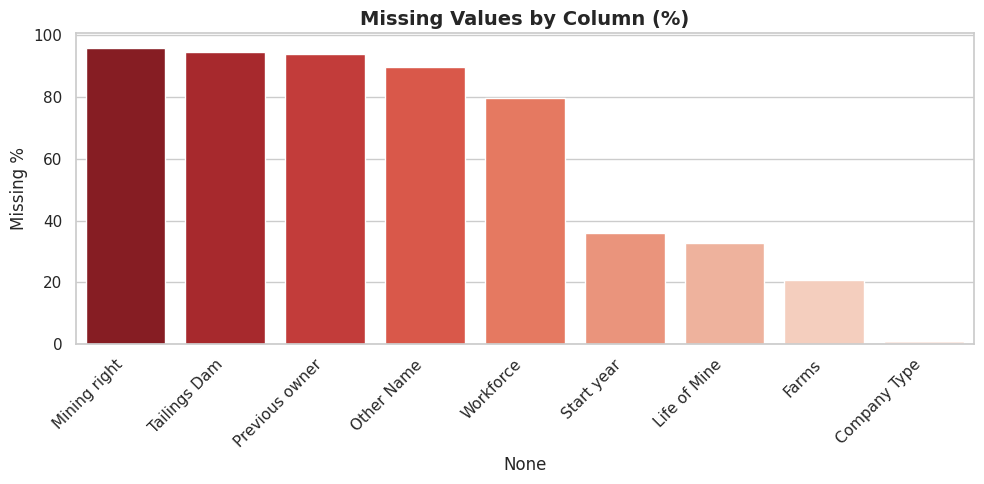

Missing values chart saved.


In [9]:
# Analysing Missing Values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

print('Missing Values Report:')
print(missing_df)

# Missing Values Plot
plt.figure(figsize=(10, 5))
sns.barplot(x=missing_df.index, y='Missing %', data=missing_df, palette='Reds_r')
plt.title('Missing Values by Column (%)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Missing %')
plt.tight_layout()
plt.savefig('missing_values.png', dpi=150)
plt.show()
print('Missing values chart saved.')

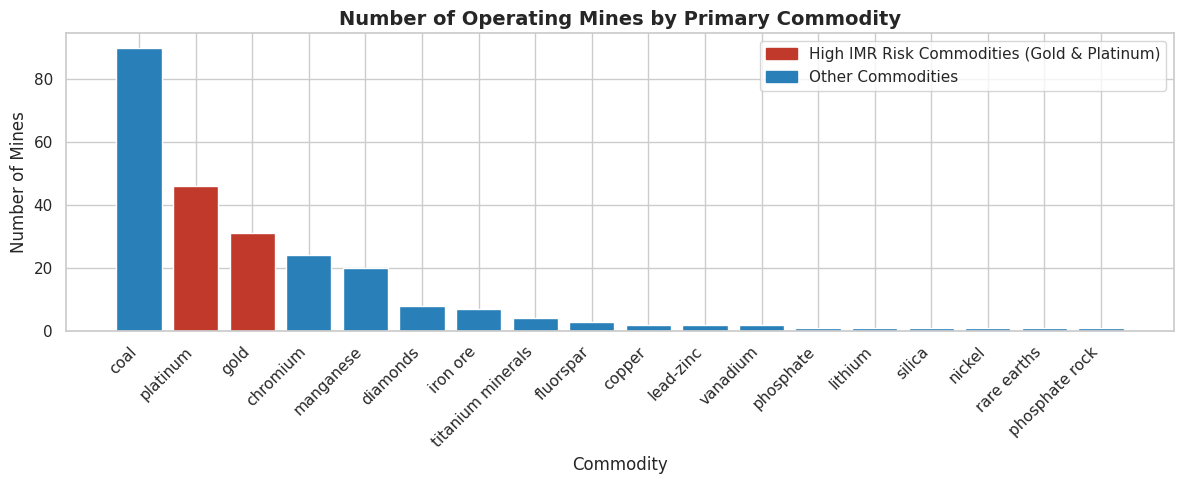

Commodity distribution chart saved.


In [10]:
# Commodity distribution
plt.figure(figsize=(12, 5))
commodity_counts = df['Primary Commodity'].value_counts()
colors = ['#C0392B' if c in ['gold', 'platinum'] else '#2980B9' for c in commodity_counts.index]
bars = plt.bar(commodity_counts.index, commodity_counts.values, color=colors, edgecolor='white')
plt.title('Number of Operating Mines by Primary Commodity', fontsize=14, fontweight='bold')
plt.xlabel('Commodity')
plt.ylabel('Number of Mines')
plt.xticks(rotation=45, ha='right')
red_patch = mpatches.Patch(color='#C0392B', label='High IMR Risk Commodities (Gold & Platinum)')
blue_patch = mpatches.Patch(color='#2980B9', label='Other Commodities')
plt.legend(handles=[red_patch, blue_patch])
plt.tight_layout()
plt.savefig('commodity_distribution.png', dpi=150)
plt.show()
print('Commodity distribution chart saved.')

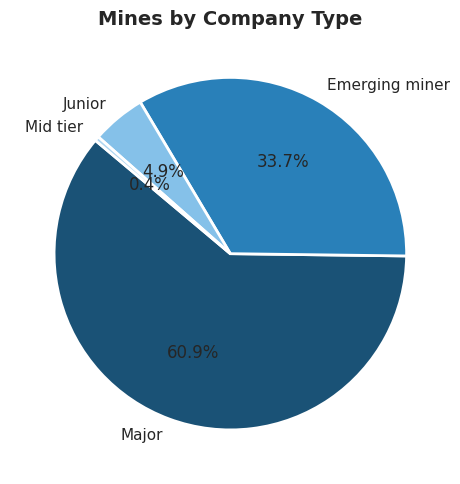

Company type chart saved.


In [11]:
# Company type distribution
plt.figure(figsize=(7, 5))
company_counts = df['Company Type'].value_counts()
plt.pie(company_counts.values, labels=company_counts.index,
        autopct='%1.1f%%', colors=['#1A5276','#2980B9','#85C1E9','#AED6F1'],
        startangle=140, wedgeprops=dict(edgecolor='white', linewidth=2))
plt.title('Mines by Company Type', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('company_type.png', dpi=150)
plt.show()
print('Company type chart saved.')

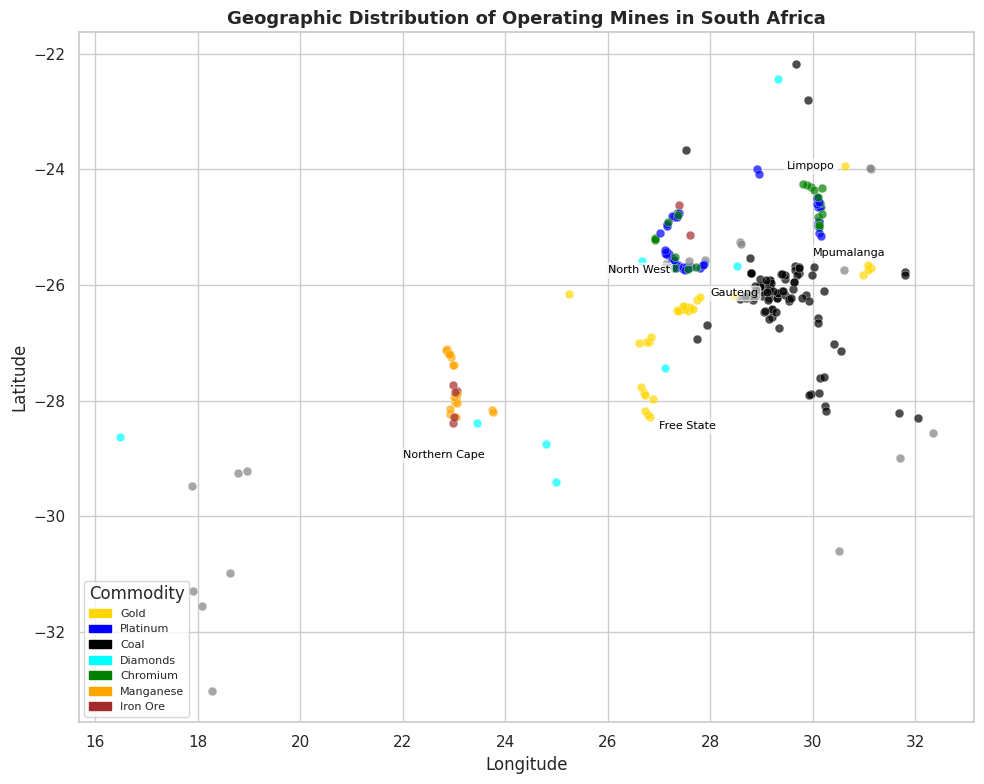

 Geographic map saved.


In [12]:
# Geographic distribution (map plot)
plt.figure(figsize=(10, 8))
commodity_colors = {
    'gold': 'gold', 'platinum': 'blue', 'coal': 'black',
    'diamonds': 'cyan', 'chromium': 'green', 'manganese': 'orange',
    'iron ore': 'brown', 'default': 'grey'
}
for _, row in df.iterrows():
    color = commodity_colors.get(row['Primary Commodity'], 'grey')
    plt.scatter(row['Longitude'], row['Latitude'], c=color, s=40, alpha=0.7, edgecolors='white', linewidth=0.3)

# Add province labels for hotspot provinces
provinces = {
    'Gauteng': (28.0, -26.2),
    'North West': (26.0, -25.8),
    'Free State': (27.0, -28.5),
    'Mpumalanga': (30.0, -25.5),
    'Limpopo': (29.5, -24.0),
    'Northern Cape': (22.0, -29.0)
}
for prov, (lon, lat) in provinces.items():
    plt.annotate(prov, (lon, lat), fontsize=8, color='black',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.6))

# Legend
handles = [mpatches.Patch(color=v, label=k.title()) for k, v in commodity_colors.items() if k != 'default']
plt.legend(handles=handles, title='Commodity', loc='lower left', fontsize=8)
plt.title('Geographic Distribution of Operating Mines in South Africa', fontsize=13, fontweight='bold')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.savefig('mines_map.png', dpi=150)
plt.show()
print(' Geographic map saved.')

---
## (4) Data Cleaning & Preparation

In [13]:
# Cleaned Dataset
df_clean = df.copy()

#  Deleting columns with too many missing values (>80%)/not useful

cols_to_drop = ['Other Name', 'Mining right', 'Tailings Dam', 'Previous owner', 'Farms']
df_clean.drop(columns=cols_to_drop, inplace=True)
print(f'Dropped {len(cols_to_drop)} low-quality columns')

# Standardising text columns to lowercase
text_cols = ['Company Type', 'Primary Commodity', 'Mining Method']
for col in text_cols:
    df_clean[col] = df_clean[col].str.strip().str.lower()

#  Filling missing Company Type with 'unknown'
df_clean['Company Type'].fillna('unknown', inplace=True)

# Handle Life of Mine: fill missing with median
median_lom = df_clean['Life of Mine'].median()
df_clean['Life of Mine'].fillna(median_lom, inplace=True)

#  Handle Start Year: fill missing with median
# Remove non-numeric start years first
df_clean['Start year'] = pd.to_numeric(df_clean['Start year'], errors='coerce')
median_sy = df_clean['Start year'].median()
df_clean['Start year'].fillna(median_sy, inplace=True)

# Handle Workforce: fill missing with median
df_clean['Workforce'] = pd.to_numeric(df_clean['Workforce'], errors='coerce')
median_wf = df_clean['Workforce'].median()
df_clean['Workforce'].fillna(median_wf, inplace=True)

# Standardise Mining Method (clean up variations)
df_clean['Mining Method'] = df_clean['Mining Method'].str.strip()
df_clean['Mining Method'] = df_clean['Mining Method'].replace({
    'open cast ': 'open cast',
    'conventional deep underground': 'deep underground',
    'mechanised conventional underground': 'underground',
    'mechanised underground': 'underground',
    'underground mechanised': 'underground',
    'conventional underground': 'underground',
    'underground & open cast': 'underground',
    'underground, open cast': 'underground',
    'underground, open pit': 'underground',
    'open cast, underground': 'underground'
})

print(f'Data cleaning complete')
print(f'Clean dataset shape: {df_clean.shape}')
print(f'\nRemaining missing values:')
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Dropped 5 low-quality columns
Data cleaning complete!
Clean dataset shape: (245, 11)

Remaining missing values:
Series([], dtype: int64)


---
## (5) Feature Engineering
> This is where we create the variables that the model will use to predict illegal mining risk.
> Each feature is grounded in the literature and the real-world dynamics of zama-zama activity.

In [15]:
# FEATURE 1: High-Risk Commodity
# Gold and platinum mines are the primary targets of zama-zama operations
# (Global Africa Network, 2024; Wikipedia, 2026)
df_clean['high_risk_commodity'] = df_clean['Primary Commodity'].apply(
    lambda x: 1 if x in ['gold', 'platinum'] else 0
)

# FEATURE 2: Underground Mining Method
# Underground mines provide easier access and concealment for illegal miners
# (Bester & Uys, 2023)
df_clean['is_underground'] = df_clean['Mining Method'].apply(
    lambda x: 1 if 'underground' in str(x) else 0
)

#  FEATURE 3: High-Risk Province
# Classify mines by province using GPS coordinates
# Hotspot provinces: Gauteng, North West, Free State, Mpumalanga
def classify_province(lat, lon):
    """Classify a mine into a South African province based on coordinates."""
    if lat is None or lon is None:
        return 'Unknown'
    # Approximate bounding boxes for SA provinces
    if -26.5 <= lat <= -25.5 and 27.5 <= lon <= 29.0:
        return 'Gauteng'
    elif -27.5 <= lat <= -24.0 and 24.5 <= lon <= 28.5:
        return 'North West'
    elif -30.5 <= lat <= -26.5 and 24.5 <= lon <= 29.5:
        return 'Free State'
    elif -26.5 <= lat <= -24.0 and 29.0 <= lon <= 32.5:
        return 'Mpumalanga'
    elif -24.0 <= lat <= -22.0 and 27.0 <= lon <= 32.0:
        return 'Limpopo'
    elif -34.0 <= lat <= -30.5 and 17.0 <= lon <= 27.0:
        return 'Northern Cape'
    elif -34.5 <= lat <= -30.0 and 17.0 <= lon <= 22.0:
        return 'Western Cape'
    elif -31.5 <= lat <= -28.0 and 22.0 <= lon <= 30.5:
        return 'Eastern Cape'
    elif -31.5 <= lat <= -28.0 and 29.0 <= lon <= 32.5:
        return 'KwaZulu-Natal'
    else:
        return 'Other'

df_clean['Province'] = df_clean.apply(
    lambda row: classify_province(row['Latitude'], row['Longitude']), axis=1
)

# High-risk provinces flag
hotspot_provinces = ['Gauteng', 'North West', 'Free State', 'Mpumalanga']
df_clean['in_hotspot_province'] = df_clean['Province'].apply(
    lambda x: 1 if x in hotspot_provinces else 0
)

print('Province distribution:')
print(df_clean['Province'].value_counts())

#  FEATURE 4: Mine Age
# Older mines have more abandoned sections — higher illegal mining risk
current_year = 2026
df_clean['mine_age'] = current_year - df_clean['Start year']
# Categorise: young (<30 yrs), medium (30-60), old (>60)
df_clean['age_category'] = pd.cut(
    df_clean['mine_age'],
    bins=[0, 30, 60, 200],
    labels=['young', 'medium', 'old']
)

#  FEATURE 5: Workforce Size
# Large workforce = more activity = more complex security = higher illegal mining risk
df_clean['large_workforce'] = df_clean['Workforce'].apply(
    lambda x: 1 if x > df_clean['Workforce'].median() else 0
)

# FEATURE 6: Company Type Risk
# Major companies are more targeted; junior/emerging miners may lack security
company_risk_map = {'major': 3, 'mid tier': 2, 'junior': 2, 'emerging miner': 1, 'unknown': 1}
df_clean['company_risk_score'] = df_clean['Company Type'].map(company_risk_map).fillna(1)

# FEATURE 7: Remaining Life of Mine
# Mines near end of life are more vulnerable (less investment in security)
df_clean['years_remaining'] = df_clean['Life of Mine'] - current_year
df_clean['years_remaining'] = df_clean['years_remaining'].clip(lower=0)
df_clean['near_end_of_life'] = df_clean['years_remaining'].apply(
    lambda x: 1 if x <= 10 else 0
)

print('\n Feature engineering complete')
print(f'New features created: high_risk_commodity, is_underground, Province,'
      f' in_hotspot_province, mine_age, age_category, large_workforce,'
      f' company_risk_score, years_remaining, near_end_of_life')

Province distribution:
Province
Mpumalanga       81
North West       52
Gauteng          39
Other            32
Free State       12
Eastern Cape     12
Limpopo           8
KwaZulu-Natal     5
Northern Cape     4
Name: count, dtype: int64

 Feature engineering complete
New features created: high_risk_commodity, is_underground, Province, in_hotspot_province, mine_age, age_category, large_workforce, company_risk_score, years_remaining, near_end_of_life


---
## STEP 6 — Build the IMR Risk Score (Rule-Based)
> Since we do not have labelled illegal mining incident data per mine,
> we first construct a **domain-knowledge-based IMR score** using weighted risk factors.
> This score then becomes our target variable for the ML model.

In [16]:
# IMR Score Formula
# Each risk factor is weighted based on its documented contribution to
# illegal mining risk in the literature
#
# Weights (total = 100 points):
#   High-risk commodity (gold/platinum)  : 30 points
#   In hotspot province                  : 25 points
#   Underground mining method            : 20 points
#   Mine age (older = higher risk)       : 10 points
#   Company type risk score              : 8  points
#   Near end of life                     : 7  points

def calculate_imr_score(row):
    score = 0

    # Factor 1: High-risk commodity (30 pts)
    score += 30 if row['high_risk_commodity'] == 1 else 0

    # Factor 2: Hotspot province (25 pts)
    score += 25 if row['in_hotspot_province'] == 1 else 0

    # Factor 3: Underground method (20 pts)
    score += 20 if row['is_underground'] == 1 else 0

    # Factor 4: Mine age (10 pts scaled)
    age = row['mine_age']
    if age > 100:
        score += 10
    elif age > 60:
        score += 7
    elif age > 30:
        score += 4
    else:
        score += 1

    # Factor 5: Company type risk (8 pts scaled)
    crs = row['company_risk_score']
    score += int((crs / 3) * 8)

    # Factor 6: Near end of life (7 pts)
    score += 7 if row['near_end_of_life'] == 1 else 0

    return min(score, 100)  # Cap at 100

df_clean['IMR_Score'] = df_clean.apply(calculate_imr_score, axis=1)

# Risk Categories
def categorise_risk(score):
    if score >= 70:
        return 'High Risk'
    elif score >= 40:
        return 'Medium Risk'
    else:
        return 'Low Risk'

df_clean['Risk_Category'] = df_clean['IMR_Score'].apply(categorise_risk)

print(' IMR Scores calculated')
print(f'\nIMR Score Statistics:')
print(df_clean['IMR_Score'].describe())
print(f'\nRisk Category Distribution:')
print(df_clean['Risk_Category'].value_counts())

 IMR Scores calculated

IMR Score Statistics:
count    245.000000
mean      50.624490
std       29.018469
min        3.000000
25%       31.000000
50%       44.000000
75%       84.000000
max      100.000000
Name: IMR_Score, dtype: float64

Risk Category Distribution:
Risk_Category
Low Risk       109
High Risk       71
Medium Risk     65
Name: count, dtype: int64


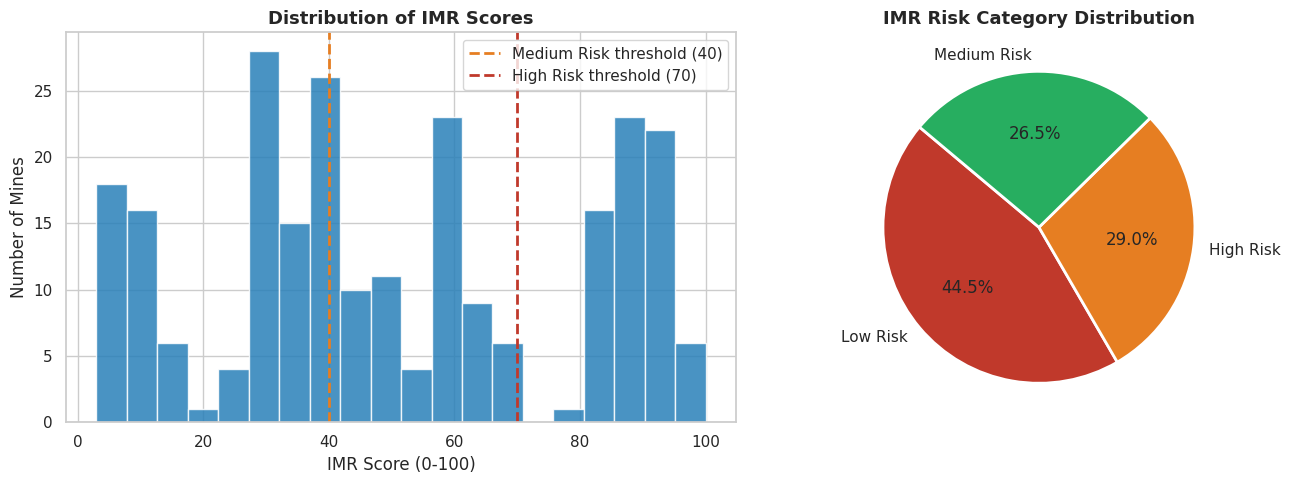

IMR distribution charts saved.


In [18]:
# Visualising IMR Score Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of IMR Scores
colors_map = df_clean['Risk_Category'].map({'High Risk': '#C0392B', 'Medium Risk': '#E67E22', 'Low Risk': '#27AE60'})
axes[0].hist(df_clean['IMR_Score'], bins=20, color='#2980B9', edgecolor='white', alpha=0.85)
axes[0].axvline(40, color='#E67E22', linestyle='--', linewidth=2, label='Medium Risk threshold (40)')
axes[0].axvline(70, color='#C0392B', linestyle='--', linewidth=2, label='High Risk threshold (70)')
axes[0].set_title('Distribution of IMR Scores', fontsize=13, fontweight='bold')
axes[0].set_xlabel('IMR Score (0-100)')
axes[0].set_ylabel('Number of Mines')
axes[0].legend()

# Risk Category Pie Chart
risk_counts = df_clean['Risk_Category'].value_counts()
axes[1].pie(risk_counts.values,
            labels=risk_counts.index,
            autopct='%1.1f%%',
            colors=['#C0392B', '#E67E22', '#27AE60'],
            startangle=140,
            wedgeprops=dict(edgecolor='white', linewidth=2))
axes[1].set_title('IMR Risk Category Distribution', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('imr_distribution.png', dpi=150)
plt.show()
print('IMR distribution charts saved.')

In [19]:
# Top 20 Highest Risk Mines
top20 = df_clean[['Mine Name', 'Owner', 'Primary Commodity', 'Province', 'IMR_Score', 'Risk_Category']]\
    .sort_values('IMR_Score', ascending=False).head(20)

print(' Top 20 Highest IMR Risk Mines:')
print(top20.to_string(index=False))

 Top 20 Highest IMR Risk Mines:
        Mine Name                 Owner Primary Commodity   Province  IMR_Score Risk_Category
           Tumela        Anglo Platinum          platinum North West        100     High Risk
      New Consort Pan African Resources              gold Mpumalanga        100     High Risk
         Target 1               Harmony              gold Free State         97     High Risk
    Driefontein 1    Sibanye-Stillwater              gold North West         97     High Risk
 Masimong 5 shaft               Harmony              gold Free State         97     High Risk
      Kusasalethu               Harmony              gold North West         97     High Risk
          Kloof 8    Sibanye-Stillwater              gold    Gauteng         94     High Risk
          Kloof 7    Sibanye-Stillwater              gold    Gauteng         94     High Risk
Beatrix No1 Shaft    Sibanye Stillwater              gold Free State         94     High Risk
          Kloof 1    Sibanye

---
## (7) Train Machine Learning Models
> We use the IMR Risk Category (High / Medium / Low) as the target variable
> and train three models: Logistic Regression, Random Forest, and XGBoost.
> We then compare their performance.

In [20]:
#  Prepare features for ML

# Select feature columns
feature_cols = [
    'high_risk_commodity',
    'is_underground',
    'in_hotspot_province',
    'mine_age',
    'large_workforce',
    'company_risk_score',
    'near_end_of_life',
    'years_remaining',
    'Workforce'
]

X = df_clean[feature_cols].copy()

# Encode target variable(Risk Category)
le = LabelEncoder()
y = le.fit_transform(df_clean['Risk_Category'])  # High=0, Low=1, Medium=2

print(f'Features ready: {X.shape[0]} samples × {X.shape[1]} features')
print(f'Target classes: {list(le.classes_)}')
print(f'Class distribution: {dict(zip(le.classes_, np.bincount(y)))}')

Features ready: 245 samples × 9 features
Target classes: ['High Risk', 'Low Risk', 'Medium Risk']
Class distribution: {'High Risk': np.int64(71), 'Low Risk': np.int64(109), 'Medium Risk': np.int64(65)}


In [21]:
#  Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Train set: {X_train.shape[0]} samples')
print(f'Test set:  {X_test.shape[0]} samples')

Train set: 196 samples
Test set:  49 samples


In [22]:
#  MODEL 1: Logistic Regression (Baseline)
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)
lr_acc = accuracy_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred, average='weighted')

print(' Logistic Regression (Baseline)')
print(f'   Accuracy : {lr_acc:.4f} ({lr_acc*100:.1f}%)')
print(f'   F1 Score : {lr_f1:.4f}')
print(f'\n   Classification Report:')
print(classification_report(y_test, lr_pred, target_names=le.classes_))

 Logistic Regression (Baseline)
   Accuracy : 0.9796 (98.0%)
   F1 Score : 0.9794

   Classification Report:
              precision    recall  f1-score   support

   High Risk       1.00      1.00      1.00        14
    Low Risk       0.96      1.00      0.98        22
 Medium Risk       1.00      0.92      0.96        13

    accuracy                           0.98        49
   macro avg       0.99      0.97      0.98        49
weighted avg       0.98      0.98      0.98        49



In [23]:
# MODEL 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=3,
    random_state=42,
    class_weight='balanced'
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred, average='weighted')

print('Random Forest')
print(f'   Accuracy : {rf_acc:.4f} ({rf_acc*100:.1f}%)')
print(f'   F1 Score : {rf_f1:.4f}')
print(f'\n   Classification Report:')
print(classification_report(y_test, rf_pred, target_names=le.classes_))

Random Forest
   Accuracy : 1.0000 (100.0%)
   F1 Score : 1.0000

   Classification Report:
              precision    recall  f1-score   support

   High Risk       1.00      1.00      1.00        14
    Low Risk       1.00      1.00      1.00        22
 Medium Risk       1.00      1.00      1.00        13

    accuracy                           1.00        49
   macro avg       1.00      1.00      1.00        49
weighted avg       1.00      1.00      1.00        49



In [24]:
# MODEL 3: XGBoost
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_acc = accuracy_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred, average='weighted')

print(' XGBoost')
print(f'   Accuracy : {xgb_acc:.4f} ({xgb_acc*100:.1f}%)')
print(f'   F1 Score : {xgb_f1:.4f}')
print(f'\n   Classification Report:')
print(classification_report(y_test, xgb_pred, target_names=le.classes_))

 XGBoost
   Accuracy : 0.9592 (95.9%)
   F1 Score : 0.9593

   Classification Report:
              precision    recall  f1-score   support

   High Risk       0.93      1.00      0.97        14
    Low Risk       1.00      0.95      0.98        22
 Medium Risk       0.92      0.92      0.92        13

    accuracy                           0.96        49
   macro avg       0.95      0.96      0.96        49
weighted avg       0.96      0.96      0.96        49



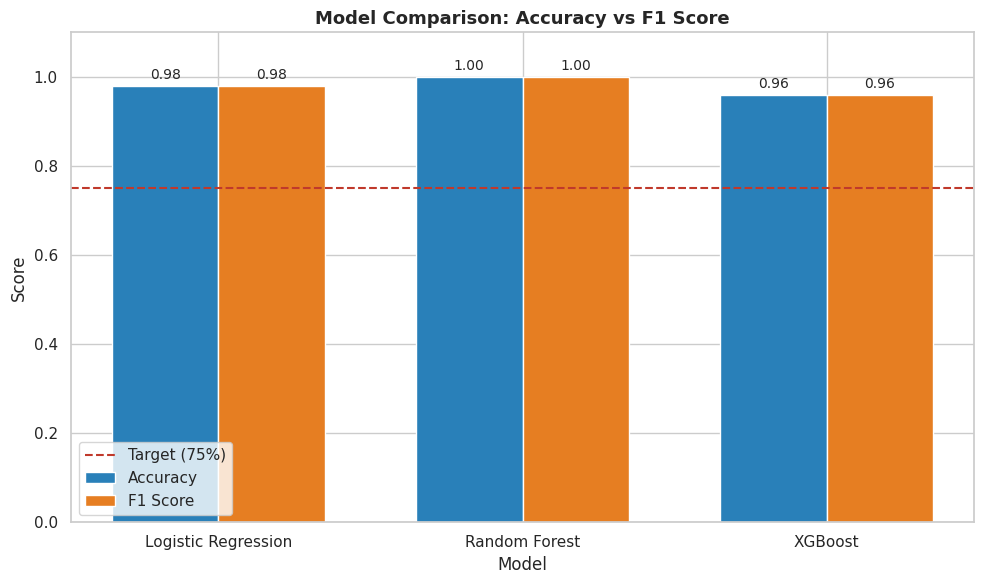

Model comparison chart saved.


In [25]:
# Model Comparison Chart
models = ['Logistic Regression', 'Random Forest', 'XGBoost']
accuracies = [lr_acc, rf_acc, xgb_acc]
f1_scores = [lr_f1, rf_f1, xgb_f1]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, accuracies, width, label='Accuracy', color='#2980B9', edgecolor='white')
bars2 = ax.bar(x + width/2, f1_scores, width, label='F1 Score', color='#E67E22', edgecolor='white')

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Model Comparison: Accuracy vs F1 Score', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1.1)
ax.axhline(0.75, color='#C0392B', linestyle='--', linewidth=1.5, label='Target (75%)')
ax.legend()

# Add value labels
for bar in bars1:
    ax.annotate(f'{bar.get_height():.2f}', xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=10)
for bar in bars2:
    ax.annotate(f'{bar.get_height():.2f}', xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()
print('Model comparison chart saved.')

---
## (8) Model Evaluation (ROC-AUC, Confusion Matrix, Cross-Validation)

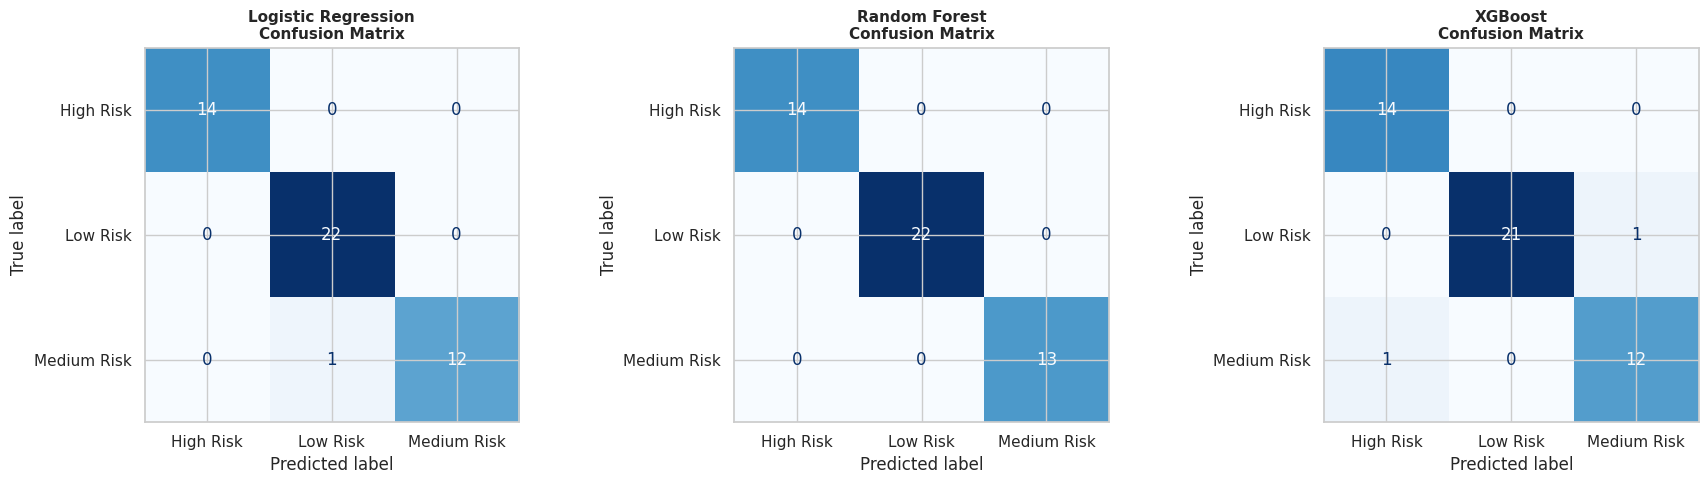

 Confusion matrices saved.


In [26]:
#  Confusion Matrix for Best Model (Random Forest)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, pred) in zip(axes, [
    ('Logistic Regression', lr_pred),
    ('Random Forest', rf_pred),
    ('XGBoost', xgb_pred)
]):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{model_name}\nConfusion Matrix', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150)
plt.show()
print(' Confusion matrices saved.')

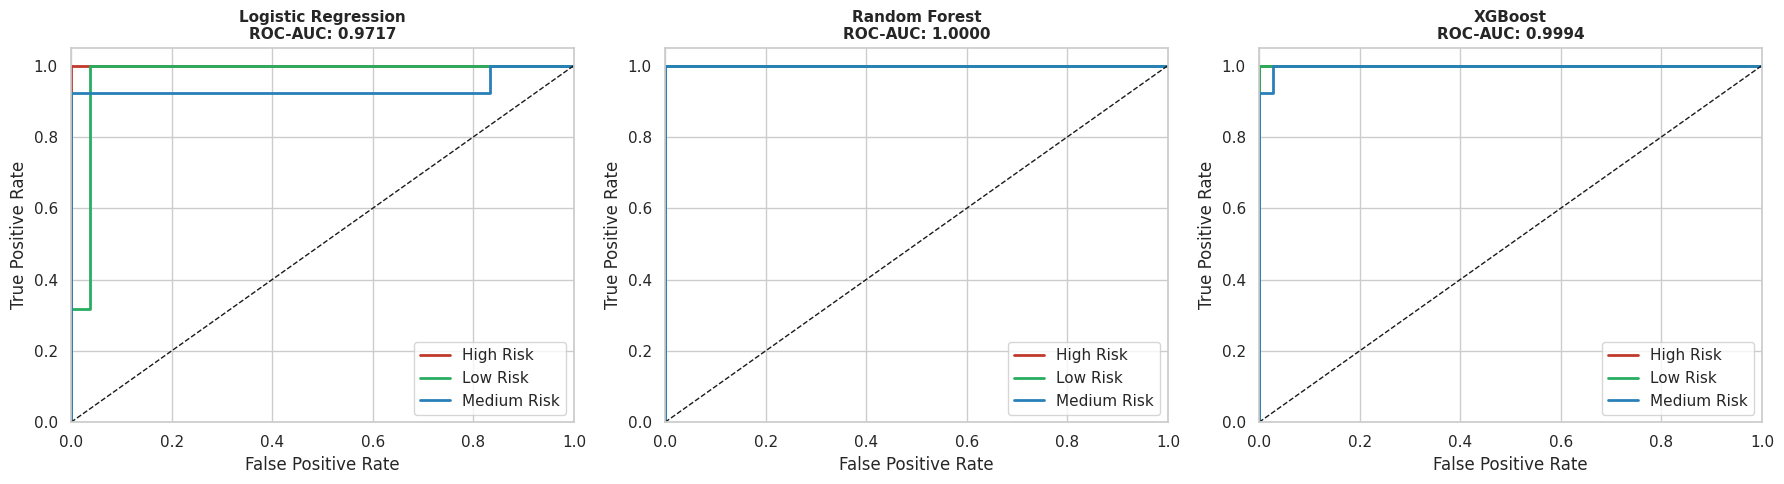

ROC curves saved.


In [27]:
#  ROC-AUC (One-vs-Rest for multiclass)
from sklearn.preprocessing import label_binarize

y_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = 3

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, model, X_eval) in zip(axes, [
    ('Logistic Regression', lr_model, X_test_scaled),
    ('Random Forest', rf_model, X_test),
    ('XGBoost', xgb_model, X_test)
]):
    y_prob = model.predict_proba(X_eval)
    roc_auc = roc_auc_score(y_bin, y_prob, multi_class='ovr', average='weighted')

    colors = ['#C0392B', '#27AE60', '#2980B9']
    for i, color in enumerate(colors):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
        ax.plot(fpr, tpr, color=color, lw=2, label=f'{le.classes_[i]}')

    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_title(f'{model_name}\nROC-AUC: {roc_auc:.4f}', fontsize=11, fontweight='bold')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(loc='lower right')
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150)
plt.show()
print('ROC curves saved.')

In [28]:
# K-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(' 5-Fold Cross Validation Results:')
print('=' * 50)

for model_name, model, X_eval in [
    ('Logistic Regression', lr_model, X_train_scaled),
    ('Random Forest', rf_model, X_train),
    ('XGBoost', xgb_model, X_train)
]:
    scores = cross_val_score(model, X_eval, y_train, cv=cv, scoring='accuracy')
    print(f'{model_name}:')
    print(f'   Mean Accuracy : {scores.mean():.4f} ({scores.mean()*100:.1f}%)')
    print(f'   Std Dev       : ±{scores.std():.4f}')
    print(f'   All Folds     : {[round(s, 3) for s in scores]}')
    print()

 5-Fold Cross Validation Results:
Logistic Regression:
   Mean Accuracy : 0.9442 (94.4%)
   Std Dev       : ±0.0431
   All Folds     : [np.float64(0.875), np.float64(0.949), np.float64(0.923), np.float64(1.0), np.float64(0.974)]

Random Forest:
   Mean Accuracy : 0.9290 (92.9%)
   Std Dev       : ±0.0427
   All Folds     : [np.float64(0.85), np.float64(0.949), np.float64(0.949), np.float64(0.923), np.float64(0.974)]

XGBoost:
   Mean Accuracy : 0.9340 (93.4%)
   Std Dev       : ±0.0295
   All Folds     : [np.float64(0.875), np.float64(0.949), np.float64(0.949), np.float64(0.949), np.float64(0.949)]



---
##  (9) SHAP Interpretability Analysis
> SHAP values explain *why* each mine received its IMR score.
> This is critical for communicating results to investors.

Computing SHAP values


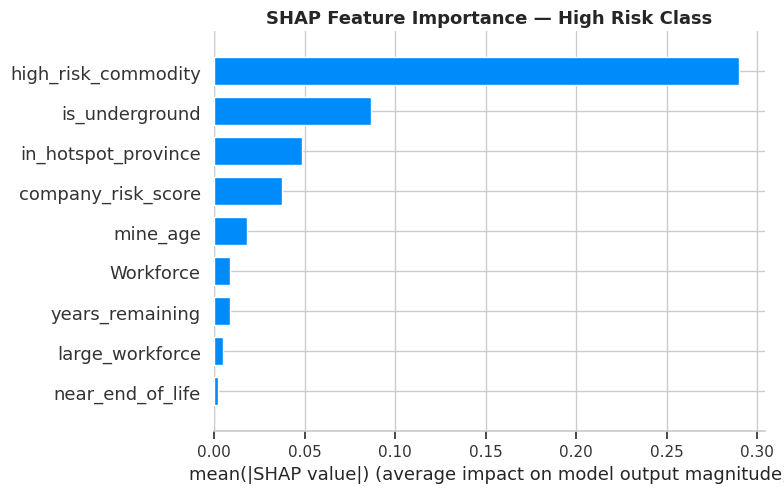

SHAP feature importance chart saved.


In [29]:
# SHAP for Random Forest
print('Computing SHAP values')

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)


# We extract class 0 (High Risk)
if isinstance(shap_values, list):
    # Older SHAP
    shap_high_risk = shap_values[0]
else:
    # Newer SHAP
    shap_high_risk = shap_values[:, :, 0]

# Feature importance bar plot
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_high_risk,
    X_test,
    feature_names=feature_cols,
    plot_type='bar',
    show=False
)
plt.title('SHAP Feature Importance — High Risk Class', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('SHAP feature importance chart saved.')

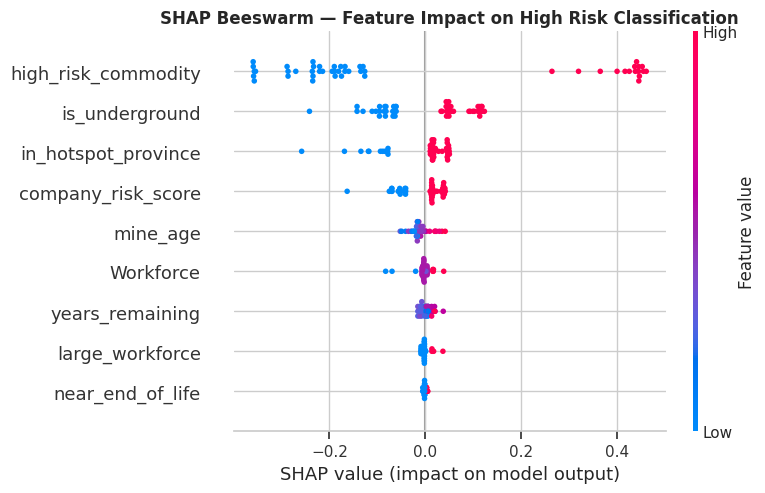

 SHAP beeswarm chart saved.


In [30]:
# SHAP Beeswarm Plot
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_high_risk,
    X_test,
    feature_names=feature_cols,
    show=False
)
plt.title('SHAP Beeswarm — Feature Impact on High Risk Classification', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()
print(' SHAP beeswarm chart saved.')

---
## STEP 10 — Export Results for Power BI Dashboard

In [32]:
#  Prepare final output dataframe
output_cols = [
    'MineID', 'Mine Name', 'Owner', 'Company Type', 'Primary Commodity',
    'Mining Method', 'Province', 'Latitude', 'Longitude',
    'Workforce', 'mine_age', 'years_remaining',
    'high_risk_commodity', 'is_underground', 'in_hotspot_province',
    'IMR_Score', 'Risk_Category'
]

df_output = df_clean[output_cols].copy()

# Rename for readability in Power BI
df_output.rename(columns={
    'MineID': 'Mine ID',
    'Company Type': 'Company Type',
    'Primary Commodity': 'Commodity',
    'Mining Method': 'Mining Method',
    'mine_age': 'Mine Age (Years)',
    'years_remaining': 'Years Remaining',
    'high_risk_commodity': 'High Risk Commodity (1=Yes)',
    'is_underground': 'Underground Mine (1=Yes)',
    'in_hotspot_province': 'Hotspot Province (1=Yes)',
    'IMR_Score': 'IMR Score (0-100)',
    'Risk_Category': 'Risk Category'
}, inplace=True)

# Save to Excel for Power BI
df_output.to_excel('IMR_Scores_PowerBI.xlsx', index=False)


print(f'   Total mines: {len(df_output)}')
print(f'\n   Risk Category Summary:')
print(df_output['Risk Category'].value_counts())
print(f'\n   Top 10 Highest Risk Mines:')
print(df_output[['Mine Name', 'Owner', 'Commodity', 'Province', 'IMR Score (0-100)', 'Risk Category']]\
      .sort_values('IMR Score (0-100)', ascending=False).head(10).to_string(index=False))

   Total mines: 245

   Risk Category Summary:
Risk Category
Low Risk       109
High Risk       71
Medium Risk     65
Name: count, dtype: int64

   Top 10 Highest Risk Mines:
        Mine Name                 Owner Commodity   Province  IMR Score (0-100) Risk Category
           Tumela        Anglo Platinum  platinum North West                100     High Risk
      New Consort Pan African Resources      gold Mpumalanga                100     High Risk
         Target 1               Harmony      gold Free State                 97     High Risk
    Driefontein 1    Sibanye-Stillwater      gold North West                 97     High Risk
 Masimong 5 shaft               Harmony      gold Free State                 97     High Risk
      Kusasalethu               Harmony      gold North West                 97     High Risk
          Kloof 8    Sibanye-Stillwater      gold    Gauteng                 94     High Risk
          Kloof 7    Sibanye-Stillwater      gold    Gauteng             

In [33]:
#  Download all output files
from google.colab import files

output_files = [
    'IMR_Scores_PowerBI.xlsx',
    'missing_values.png',
    'commodity_distribution.png',
    'company_type.png',
    'mines_map.png',
    'imr_distribution.png',
    'model_comparison.png',
    'confusion_matrices.png',
    'roc_curves.png',
    'shap_importance.png',
    'shap_beeswarm.png'
]

for f in output_files:
    try:
        files.download(f)
        print(f' Downloaded: {f}')
    except Exception as e:
        print(f' Could not download {f}: {e}')

print('\n All files downloaded')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Downloaded: IMR_Scores_PowerBI.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

 Downloaded: shap_importance.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Downloaded: shap_beeswarm.png

 All files downloaded


---
##  Summary

| Step | Task | Status |
|------|------|--------|
| 1 | Libraries installed & imported |completed|
| 2 | Dataset loaded (245 mines, 16 columns) |completed|
| 3 | Exploratory Data Analysis (EDA) | completed |
| 4 | Data cleaning & preparation |completed|
| 5 | Feature engineering (10 features) | completed |
| 6 | IMR Score calculated (0-100) | completed  |
| 6 | IMR Score calculated (0-100) |  completed |
| 6 | IMR Score calculated (0-100) |  completed |
| 7 | 3 ML models trained (LR, RF, XGBoost) | completed |
| 8 | Evaluation: Accuracy, F1, ROC-AUC, K-Fold CV |completed  |
| 9 | SHAP interpretability analysis | completed |
| 10 | Results exported for Power BI | completed |


